In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Nacimientos y defunciones

Las Estadísticas Vitales son el registro de los certificados de nacimiento y de defunción. Aquí se ven tres historias: la caída
de la natalidad, las desigualdades en la mortalidad infantil y los homicidios desde 1981.

Las tasas usan las proyecciones de población del DANE, que vienen con la librería. Son de **hechos registrados, sin ajustar
por subregistro**: no tienen por qué coincidir con los indicadores demográficos que publica el DANE, y al comparar en el tiempo
parte del cambio puede ser mejor registro.

In [2]:
import dane_data as dd

tasas = dd.eevv.tasas(range(1998, 2026))
tasas[["anio", "nacimientos", "defunciones", "tasa_natalidad", "tasa_mortalidad", "tasa_global_fecundidad"]].round(2).tail(8)

,anio,nacimientos,defunciones,tasa_natalidad,tasa_mortalidad,tasa_global_fecundidad
20,2018,649115,236932,13.45,4.91,1.66
21,2019,642660,244355,13.04,4.96,1.60
22,2020,629402,300853,12.49,5.97,1.52
23,2021,616914,363089,12.07,7.10,1.47
24,2022,573625,287251,11.11,5.56,1.36
25,2023,515549,268411,9.89,5.15,1.21
26,2024,453901,275778,8.63,5.24,1.06
27,2025,441537,284254,8.32,5.36,1.02


## Cada vez menos nacimientos

Los nacimientos pasaron de 720 984 en 1998 a 441 537 en 2025, y la mayor parte de la caída es reciente: en 2019 todavía eran
642 660. Con los registros, la fecundidad bajó de 2,16 hijos por mujer en 1998 a 1,02 en 2025. El pico de las defunciones es
la pandemia: de 244 355 en 2019 a 363 089 en 2021.

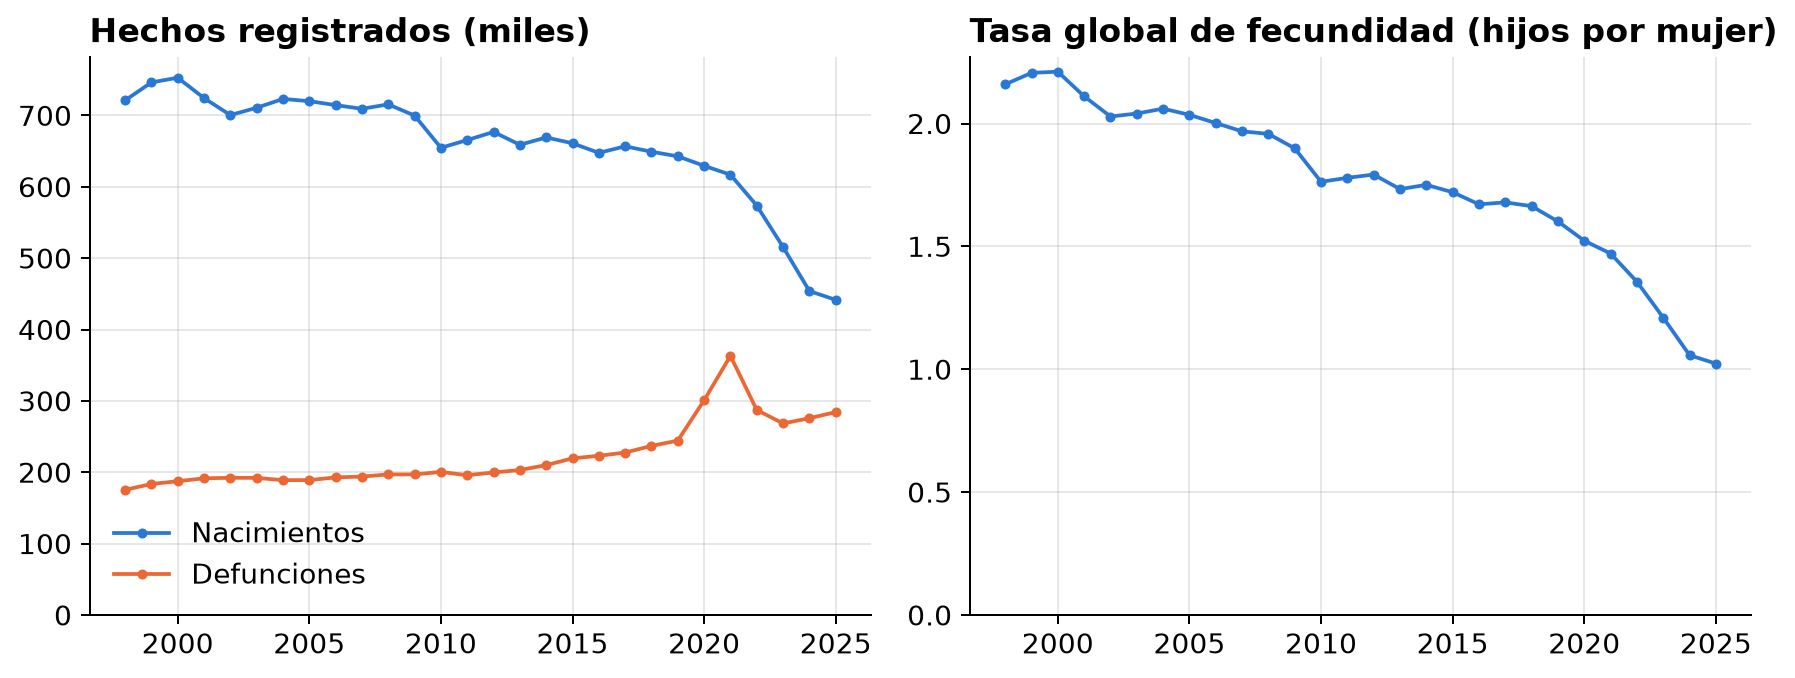

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
axes[0].plot(tasas["anio"], tasas["nacimientos"] / 1e3, marker="o", markersize=3, label="Nacimientos")
axes[0].plot(tasas["anio"], tasas["defunciones"] / 1e3, marker="o", markersize=3, label="Defunciones")
axes[0].set_title("Hechos registrados (miles)")
axes[0].set_ylim(bottom=0)
axes[0].legend(frameon=False)
axes[1].plot(tasas["anio"], tasas["tasa_global_fecundidad"], marker="o", markersize=3)
axes[1].set_title("Tasa global de fecundidad (hijos por mujer)")
axes[1].set_ylim(bottom=0)
fig.tight_layout()

## La mortalidad infantil por departamento

Las defunciones de menores de un año por cada 1.000 nacidos vivos cambian mucho según el departamento de residencia de la
madre: en 2025 van de 6,48 en Santander a 24,07 en Chocó y 29,63 en Vaupés. Con pocos nacimientos, como los 540 de Vaupés,
unas pocas defunciones mueven mucho la tasa. Donde hay más subregistro, la tasa real puede ser más alta.

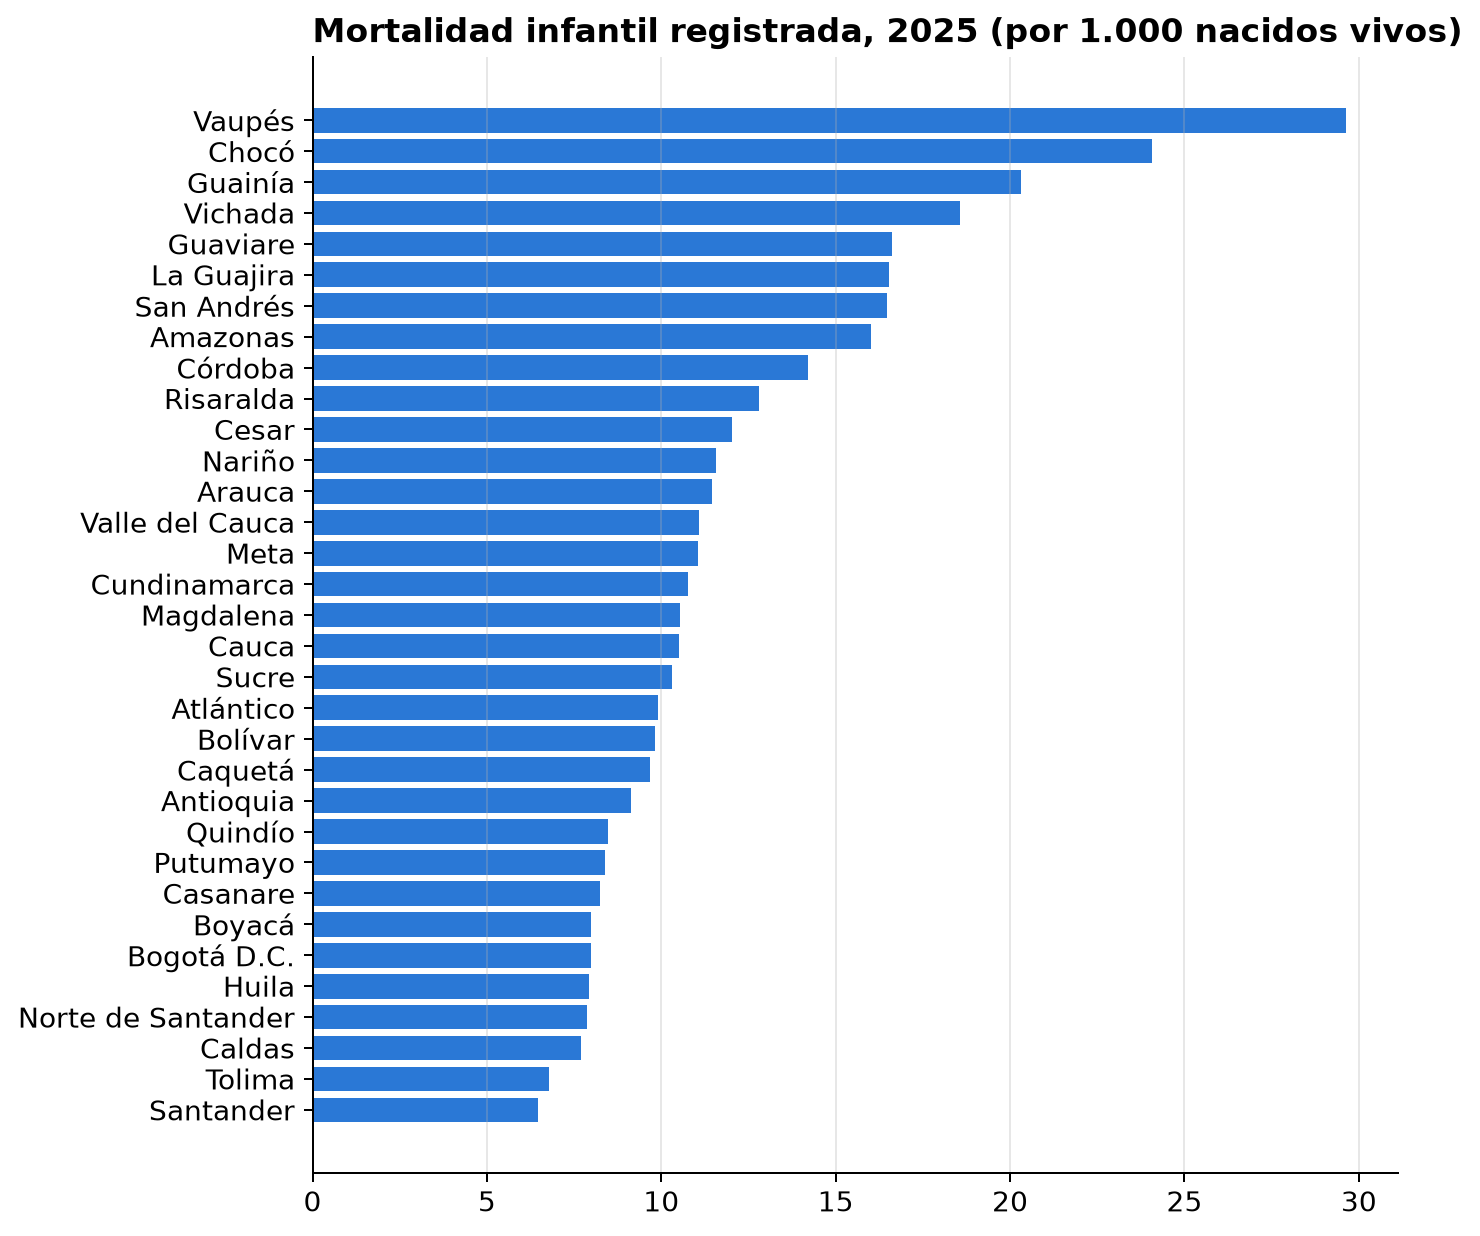

In [4]:
dptos = dd.eevv.tasas(2025, por="departamento").sort_values("mortalidad_infantil")

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(dptos["departamento"], dptos["mortalidad_infantil"])
ax.set_title("Mortalidad infantil registrada, 2025 (por 1.000 nacidos vivos)")
ax.grid(axis="y", visible=False)
fig.tight_layout()

## Los homicidios desde 1981

La lista 105 de causas es la única que cubre toda la serie, así que sirve para mirar más de cuarenta años, a pesar del cambio de
CIE-9 a CIE-10 en 1997. Se empieza en 1981 porque los archivos de 1979 y 1980 están incompletos. La tasa llegó a 86,9 por
100.000 habitantes en 1991 y a 79,1 en 2002, bajó a 25,5 en 2017 y estaba en 28,3 en 2025.

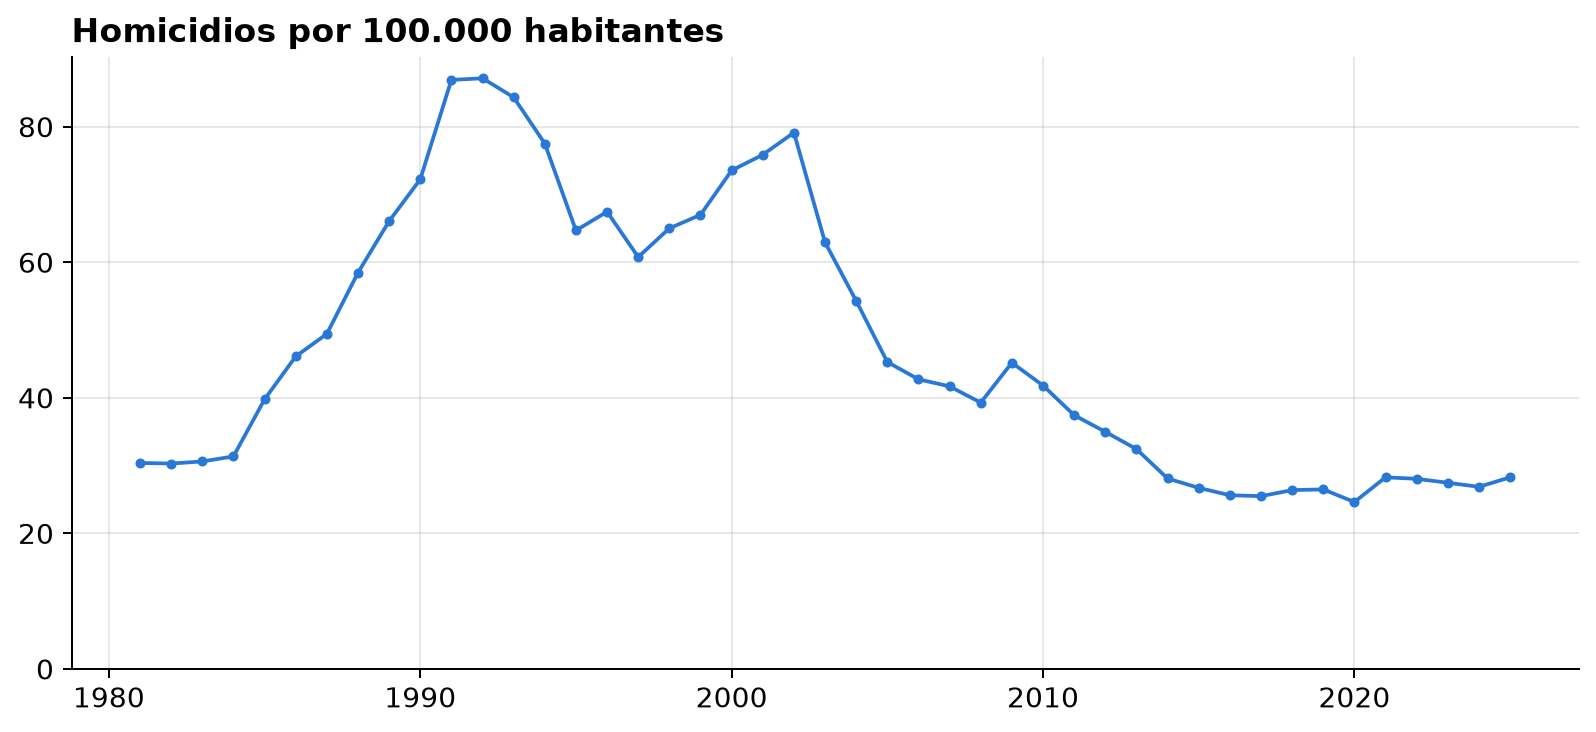

In [5]:
homicidios = dd.eevv.serie_conteos(range(1981, 2026), por="causa_105", filtros={"causa_105": ["101"]})
poblacion = dd.poblacion(range(1981, 2026))
homicidios = homicidios.astype({"anio": "int64"}).merge(poblacion, on="anio")
homicidios["tasa"] = 100_000 * homicidios["n"] / homicidios["poblacion"]

fig, ax = plt.subplots()
ax.plot(homicidios["anio"], homicidios["tasa"], marker="o", markersize=3)
ax.set_title("Homicidios por 100.000 habitantes")
ax.set_ylim(bottom=0)
fig.tight_layout()

In [6]:
homicidios[homicidios["anio"].isin([1985, 1991, 2002, 2010, 2017, 2021, 2025])][["anio", "n", "tasa"]].round(1)

,anio,n,tasa
4,1985,12101,39.8
10,1991,29413,86.9
21,2002,31807,79.1
29,2010,18439,41.8
36,2017,12093,25.5
40,2021,14457,28.3
44,2025,15003,28.3


```{seealso}
{doc}`../guia/eevv` explica las variables, las tasas y lo que cambia con los años, y {doc}`../guia/diferencias` los problemas de los
archivos.
```